In [87]:
# We import some of our usual libraries at this top level.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.stats import norm
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import cross_val_score, train_test_split, KFold, GridSearchCV,StratifiedGroupKFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, precision_score, recall_score,roc_auc_score
import shap
from scipy.interpolate import griddata
import geopandas as gpd
import seaborn as sns

In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r".*sklearn\.utils\.parallel\.delayed.*"
)

### DATA PREPARATION


In [88]:
###CLIMATE DATA

sun_flux = pd.read_csv(r"data_exercise2\data\Tswrfdaymean1961_1990.csv")
sun_flux_stats = pd.read_csv(r"data_exercise2\data\Tswrfdaymean1961_1990_stats.csv")

rain = pd.read_csv(r"data_exercise2\data\Predaymean1961_1990.csv")
rain_stats = pd.read_csv(r"data_exercise2\data\Predaymean1961_1990_stats.csv")

T_mean = pd.read_csv(r"data_exercise2\data\Tmpdaymean1961_1990.csv")
T_mean_stats = pd.read_csv(r"data_exercise2\data\Tmpdaymean1961_1990_stats.csv")

T_max = pd.read_csv(r"data_exercise2\data\Tmaxdaymean1961_1990.csv")
T_max_stats = pd.read_csv(r"data_exercise2\data\Tmaxdaymean1961_1990_stats.csv")

T_min = pd.read_csv(r"data_exercise2\data\Tmindaymean1961_1990.csv")
T_min_stats = pd.read_csv(r"data_exercise2\data\Tmindaymean1961_1990_stats.csv")

In [89]:
###LPJ-GUESS DATA
LPJ = pd.read_csv(r"data_exercise2\data\LPJ-GUESS_output_BERN1.csv")

In [90]:
###SOIL DATA
soil = pd.read_table(r"data_exercise2\data\soilmap.dat", sep=r"\s+")
soil.rename(axis=1,inplace=True,mapper={"lon":"Lon","lat":"Lat"})
soil.drop(columns=["cellfraction"],inplace=True)

In [91]:
###REGIONS DATA
regions = pd.read_table(r"data_exercise2\gridlist_pan_gfed_ISO3_UN_ecoregion.txt", sep=r"\s+")
## CAN GATHER REGION AND COUNTRY LON/LAT

In [92]:
###BIOME CLASSES
def format_rbg_string(rgbstring):
    """Transform a RGB string to a tuple of floats that matplotlib can understand"""
    rgbs = rgbstring.split(' ')
    rgbtup = tuple(float(rgb) for rgb in rgbs)
    return rgbtup

with open(r"data_exercise2\legend of biomes.txt", 'r') as f:
    lines = [ l.strip() for l in f.readlines()] # Remove endline characters and spaces
    
biome_names = lines[slice(0, len(lines), 2)] # Only use the biome names, not the colors
biome_names = [ ' '.join(l.split(' ')[1:]) for l in biome_names ] # Remove number in front of names
biome_rgbs = lines[slice(1, len(lines), 2)] # Filter out biome RGB colors
biome_rgbs = [format_rbg_string(rgbstr) for rgbstr in biome_rgbs]

In [93]:
all_data = [sun_flux,sun_flux_stats,rain,rain_stats,T_max,T_max_stats,T_mean,T_mean_stats,
            T_min,T_min_stats,soil,LPJ]

In [94]:
#Lattice check and sort by Longitud and Lattitude
temp = sun_flux[["Lon","Lat"]].sort_values(by=["Lon","Lat"]).reset_index(drop=True).copy()
for i,df in enumerate(all_data):
    df.sort_values(by=["Lon","Lat"],inplace=True)
    df.reset_index(drop=True,inplace=True)
    try:
        if not all(temp==df[["Lon","Lat"]].all()):
            raise ValueError(f"Lattice of dataframe {i} not equal to lattice of dataframe {i-1}")
        else:
            temp = df[["Lon","Lat"]]
    except Exception as e:
        print(i)

print("same lattices for all df")

same lattices for all df


In [10]:
###gridlist_pan_gfed_ISO3_UN_ecoregion.txt
###Lacks lattice points from all others

In [95]:
def test_creator(mask,target:int):
    coord = regions.loc[mask,["Lon","Lat"]]
    data = first_merge.merge(coord,on=["Lon","Lat"],how="inner").reset_index(drop=True)
    X_test = data.drop(columns=["Lon","Lat","Biome_obs"])
    y_test = (data["Biome_obs"] == target).astype(int)

    return X_test,y_test,data

In [96]:
def feature_extension(x,id,keys=["Lon","Lat"]):
    if "_" in x:
        return x
    else:
        return id+"_" + x if x not in keys else x

In [97]:
def season_swap_N(x):
    if "Spring" in x:
        return x.replace("Spring","Winter")
    
    if "Summer" in x:
        return x.replace("Summer","Spring")

    if "Fall" in x:
        return x.replace("Fall","Summer")

    if "Winter" in x:
        return x.replace("Winter","Fall")
    return x

def season_swap_S(x):
    if "Spring" in x:
        return x.replace("Spring","Summer")
    
    if "Summer" in x:
        return x.replace("Summer","Fall")

    if "Fall" in x:
        return x.replace("Fall","Winter")

    if "Winter" in x:
        return x.replace("Winter","Spring")
    return x

In [98]:
stats_dict = {"sun":sun_flux_stats,
            "rain":rain_stats,
            "Tmax":T_max_stats,
            "Tmean":T_mean_stats,
            "Tmin":T_min_stats}

for key,value in stats_dict.items():
    value.rename(axis=1,inplace=True,mapper=lambda x: feature_extension(x,key))



In [99]:
##Season swap
for key,value in stats_dict.items():
    N_value = value[value["Lat"]>=0.0].copy()
    N_value.rename(axis=1,inplace=True,mapper=lambda x: season_swap_N(x))

    S_value = value[value["Lat"]<0.0].copy()
    S_value.rename(axis=1,inplace=True,mapper=lambda x: season_swap_S(x))

    new_value = pd.concat([N_value,S_value],ignore_index=True)

    value.drop(value.index, inplace=True)
    value.drop(columns=value.columns, inplace=True)
    for col in new_value.columns:
        value[col] = new_value[col].values

In [100]:
first_merge = sun_flux_stats.copy()
for i,df in enumerate(list(stats_dict.values())[1:] + [soil]):
    try:
        first_merge = first_merge.merge(df,how="inner",on=["Lon","Lat"])
    except Exception as e:
        print(i)
        print(e)

first_merge = first_merge.merge(LPJ[["Lon","Lat","Biome_obs"]],on=["Lon","Lat"],how="inner")

In [101]:
regions_merge = first_merge.merge(regions[["Lon","Lat","Pan_2007","ISO3"]],on=["Lon","Lat"],how="inner")

### TRAINING DATA

In [138]:
europe_mask = regions["Pan_2007"].isin(["Europe"])
peninsula_mask = regions["ISO3"].isin(["ESP","PRT"]) & (regions["Lon"]>-13.0) & (regions["Lat"]>34.0)

peninsula_coord = regions.loc[peninsula_mask,["Lon","Lat"]]
europe_coord = regions.loc[europe_mask&~peninsula_mask,["Lon","Lat"]]

peninsula_data = first_merge.merge(peninsula_coord,on=["Lon","Lat"],how="inner").reset_index(drop=True)
europe_data = first_merge.merge(europe_coord,on=["Lon","Lat"],how="inner").reset_index(drop=True)

peninsula_positives = peninsula_data[peninsula_data["Biome_obs"]==12]
peninsula_negatives = peninsula_data[peninsula_data["Biome_obs"]!=12]

europe_positives = europe_data[europe_data["Biome_obs"]==12]
europe_negatives = europe_data[europe_data["Biome_obs"]!=12]
europe_negatives_sample = europe_negatives.sample(random_state=4,n=20)

In [107]:
peninsula_data["Biome_obs"].value_counts()

Biome_obs
12    96
15    66
5     50
6     43
7      2
11     2
3      2
2      1
Name: count, dtype: int64

In [ ]:
peninsula_negatives.shape[0]

166

In [ ]:
peninsula_positives.shape[0]/(peninsula_positives.shape[0]+peninsula_negatives.shape[0])

0.366412213740458

In [139]:
train = pd.concat([peninsula_data])
#train = train.sample(frac=1, random_state=4).reset_index(drop=True)

X_train = train.drop(columns=["Lon","Lat","Biome_obs"])
y_train = (train["Biome_obs"] == 12).astype(int)

In [130]:
###TRAINING NEAR LOCAL TEST TO IMPROVE NEGATIVE CLASSIFICATION
ZWE_MAR_near = ["ZAF","BWA","MOZ","ZMB","TUN","DZA"]
near_mask = regions["ISO3"].isin(ZWE_MAR_near)
near_coord = regions.loc[near_mask,["Lon","Lat"]]
near_data = regions_merge.merge(near_coord,on=["Lon","Lat"],how="inner").reset_index(drop=True)

near_positives = near_data[near_data["Biome_obs"]==12]
near_negatives = near_data[near_data["Biome_obs"]!=12]

near_negative_sample = (
    near_negatives
    .groupby(["ISO3","Biome_obs"], group_keys=False)
    .apply(lambda x: x.sample(
        n=min(len(x), 5),
        random_state=42
    ),include_groups=True)
    .reset_index(drop=True)
)

near_positive_sample = (
    near_positives
    .groupby("Biome_obs", group_keys=False)
    .apply(lambda x: x.sample(
        n=min(len(x), 100),
        random_state=42,
    ),include_groups=True)
    .reset_index(drop=True)
)

near_samples = pd.concat([near_negative_sample.drop(columns=["Lon","Lat","ISO3","Pan_2007"]),
                          near_positive_sample.drop(columns=["Lon","Lat","ISO3","Pan_2007"])])
y_near_samples = (near_samples.pop("Biome_obs") == 12).astype(int)

X_train_ext = pd.concat([X_train,near_samples]).reset_index(drop=True)
y_train_ext = pd.concat([y_train,y_near_samples]).reset_index(drop=True)

C:\Users\Adri\AppData\Local\Temp\ipykernel_15112\1744241814.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(
C:\Users\Adri\AppData\Local\Temp\ipykernel_15112\1744241814.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(


### BRUTE TRAINING

In [ ]:
def build_global_train_set(df,test_region,region_col="ISO3",
    biome_col="Biome_obs",possitive_class=12,negative_ratio=1.0,random_state=4):

    rng = np.random.default_rng(random_state)

    if test_region not in df[region_col].unique():
        raise ValueError(f"Region {test_region} not in {region_col}")
    
    # Exclude test region completely
    available = df[
        df[region_col] != test_region
    ].copy()

    # -----------------------------
    # Positives
    # -----------------------------

    positives = available[
        available[biome_col] == possitive_class
    ].copy()

    n_positive = len(positives)

    if n_positive == 0:
        raise ValueError(
            f"No Dry Savanna outside {test_region}"
        )

    # -----------------------------
    # Negatives
    # -----------------------------

    negatives = available[
        available[biome_col] != possitive_class
    ].copy()

    n_negative = int(
        round(n_positive * negative_ratio)
    )

    # -----------------------------
    # Equal allocation across biomes
    # -----------------------------

    biome_groups = list(
        negatives.groupby(biome_col)
    )

    rng.shuffle(biome_groups)

    n_biomes = len(biome_groups)

    base_n = n_negative // n_biomes
    remainder = n_negative % n_biomes

    sampled = []
    selected_indices = set()

    for i, (biome, biome_data) in enumerate(
        biome_groups
    ):

        n = base_n + (
            1 if i < remainder else 0
        )

        n = min(n, len(biome_data))

        if n > 0:

            sample = biome_data.sample(
                n=n,
                random_state=int(
                    rng.integers(0, 1_000_000_000)
                )
            )

            sampled.append(sample)
            selected_indices.update(
                sample.index
            )

    sampled_negatives = pd.concat(
        sampled,
        ignore_index=False
    )

    # -----------------------------
    # Fill remaining slots
    # -----------------------------

    remaining = (
        n_negative
        - len(sampled_negatives)
    )

    if remaining > 0:

        remaining_pool = negatives[
            ~negatives.index.isin(
                selected_indices
            )
        ]

        if len(remaining_pool) < remaining:
            raise ValueError(
                "Not enough negative observations "
                "available."
            )

        extra = remaining_pool.sample(
            n=remaining,
            random_state=int(
                rng.integers(
                    0,
                    1_000_000_000
                )
            )
        )

        sampled_negatives = pd.concat(
            [
                sampled_negatives,
                extra
            ]
        )

    # -----------------------------
    # Final train
    # -----------------------------

    train_df = pd.concat(
        [
            positives,
            sampled_negatives
        ],
        ignore_index=True
    )

    train_df = train_df.sample(
        frac=1,
        random_state=random_state
    ).reset_index(drop=True)

    return train_df

In [ ]:
global_train_set = build_global_train_set(regions_merge,"ZWE",negative_ratio=1)
global_train_set["Biome_obs"]=(global_train_set["Biome_obs"]==12).astype(int)


In [ ]:
y_temp = global_train_set.pop("Biome_obs")

In [ ]:
global_train_set.drop(columns=["Lon","Lat","Pan_2007","ISO3"],inplace=True)

In [ ]:
X_train_gs, X_val_gs, y_train_gs, y_test_gs = train_test_split(global_train_set, y_temp, random_state=4, test_size=0.2,stratify=y_temp)


### TEST DATA

In [ ]:
X_test_eu = europe_data.drop(columns=["Lon","Lat","Biome_obs"])
y_test_eu = (europe_data["Biome_obs"]==12).astype(int)

In [131]:
ZWE_mask = regions["ISO3"].isin(["ZWE"])
MAR_mask = regions["ISO3"].isin(["MAR"])
AUS_mask = regions["Pan_2007"].isin(["Australia"])



X_test_ZWE,y_test_ZWE,_ = test_creator(ZWE_mask,12)
X_test_MAR,y_test_MAR,_ = test_creator(MAR_mask,12)
X_test_AUS,y_test_AUS,_ = test_creator(AUS_mask,12)



In [ ]:
#Test in country:ZWE,MAR
# Test in region: Us,AUS

### BINARY CLASSIFIER /
### MODEL VALIDATION

In [140]:
bin_class = RandomForestClassifier(random_state=4)
bin_class.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",4
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [133]:
def test(X_test,y_test):
    score_rfc_train = accuracy_score(y_train, bin_class.predict(X_train))
    score_rfc_test = accuracy_score(y_test,bin_class.predict(X_test))
    print('Accuracy of RandomForestClassifier on train data: {:.4f}'.format(score_rfc_train))
    print('Accuracy of RandomForestClassifier on test data: {:.4f}'.format(score_rfc_test))
    print("\nClassification Report:")
    print(classification_report(y_test, bin_class.predict(X_test)))

    cm = confusion_matrix(
    y_test,
    bin_class.predict(X_test),
    labels=[1,0]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Dry savannas","Not Dry savannas"]
    )

    disp.plot(cmap=plt.cm.Blues, colorbar=False)
    plt.show()

In [117]:
feature_imp = pd.DataFrame(
    {'importance':bin_class.feature_importances_},
    index=X_train.columns)
feature_imp.sort_values(by='importance', ascending=False)

,importance
sun_WinterMean,0.139630
sun_FallMean,0.123006
sun_WinterMedian,0.073381
sun_SpringMean,0.047882
sun_FallMedian,0.045444
...,...
orgC,0.001171
Tmean_SpringMedian,0.001143
Tmean_FallMedian,0.000676
silt,0.000606


Accuracy of RandomForestClassifier on train data: 1.0000
Accuracy of RandomForestClassifier on test data: 0.5221

Classification Report:
              precision    recall  f1-score   support

           0       0.55      0.64      0.59        73
           1       0.48      0.38      0.42        63

    accuracy                           0.52       136
   macro avg       0.51      0.51      0.51       136
weighted avg       0.52      0.52      0.51       136



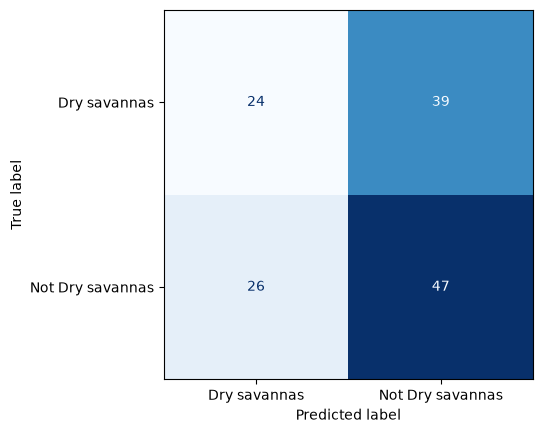

In [141]:
test(X_test_ZWE,y_test_ZWE)

Accuracy of RandomForestClassifier on train data: 1.0000
Accuracy of RandomForestClassifier on test data: 0.3043

Classification Report:
              precision    recall  f1-score   support

           0       0.23      0.03      0.05       105
           1       0.31      0.82      0.45        56

    accuracy                           0.30       161
   macro avg       0.27      0.42      0.25       161
weighted avg       0.26      0.30      0.19       161



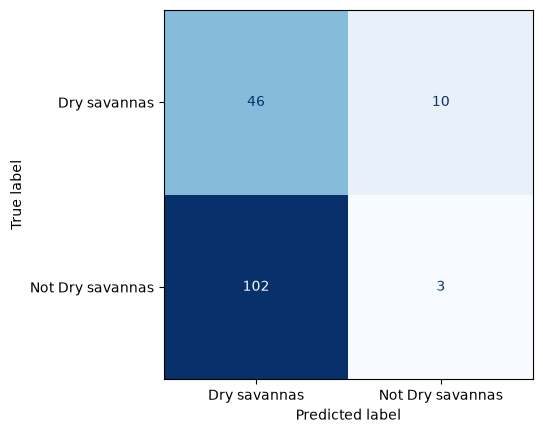

In [142]:
test(X_test_MAR,y_test_MAR)

### Peninsula vs Zimbawe CLASSIFIER


In [124]:
ZWE_data=first_merge.merge(regions.loc[ZWE_mask,["Lon","Lat"]],on=["Lon","Lat"],how="inner")

In [125]:
# Only Dry Savanna
P_DS = peninsula_data[
    peninsula_data["Biome_obs"] == 12
].copy()

ZWE_DS = ZWE_data[
    ZWE_data["Biome_obs"] == 12
].copy()

#Class
# 0 = Peninsule
# 1 = Zimbabwe
P_DS["Origin"] = 0
ZWE_DS["Origin"] = 1

origin_data = pd.concat(
    [P_DS, ZWE_DS],
    ignore_index=True
)


DATASET PARA EL MODELO
Observaciones: 126
Features: 66

Features:
['sun_WinterMean', 'sun_WinterMedian', 'sun_WinterStd', 'sun_SpringMean', 'sun_SpringMedian', 'sun_SpringStd', 'sun_SummerMean', 'sun_SummerMedian', 'sun_SummerStd', 'sun_FallMean', 'sun_FallMedian', 'sun_FallStd', 'rain_WinterMean', 'rain_WinterMedian', 'rain_WinterStd', 'rain_SpringMean', 'rain_SpringMedian', 'rain_SpringStd', 'rain_SummerMean', 'rain_SummerMedian', 'rain_SummerStd', 'rain_FallMean', 'rain_FallMedian', 'rain_FallStd', 'Tmax_WinterMean', 'Tmax_WinterMedian', 'Tmax_WinterStd', 'Tmax_SpringMean', 'Tmax_SpringMedian', 'Tmax_SpringStd', 'Tmax_SummerMean', 'Tmax_SummerMedian', 'Tmax_SummerStd', 'Tmax_FallMean', 'Tmax_FallMedian', 'Tmax_FallStd', 'Tmean_WinterMean', 'Tmean_WinterMedian', 'Tmean_WinterStd', 'Tmean_SpringMean', 'Tmean_SpringMedian', 'Tmean_SpringStd', 'Tmean_SummerMean', 'Tmean_SummerMedian', 'Tmean_SummerStd', 'Tmean_FallMean', 'Tmean_FallMedian', 'Tmean_FallStd', 'Tmin_WinterMean', 'Tmin_Win

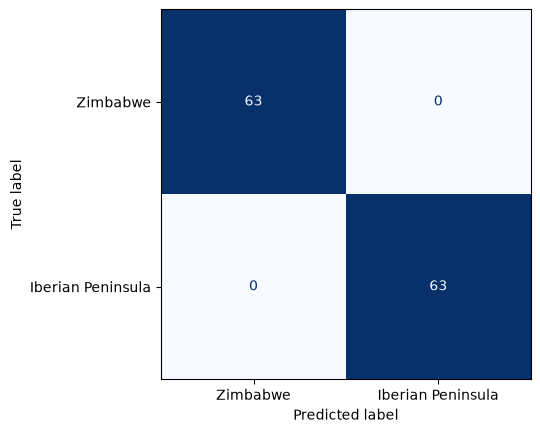

[[63  0]
 [ 0 63]]


In [126]:

##CUT OBSERVATIONS FOR EACH CLASS

n_per_class = origin_data["Origin"].value_counts().min()

origin_data = (
    origin_data
    .groupby("Origin", group_keys=False)
    .sample(
        n=n_per_class,
        random_state=42
    )
    .reset_index(drop=True)
)



##SPATIAL BLOCKS

CELL_SIZE = 2.0

origin_data["lon_block"] = np.floor(
    origin_data["Lon"] / CELL_SIZE
).astype(int)

origin_data["lat_block"] = np.floor(
    origin_data["Lat"] / CELL_SIZE
).astype(int)


origin_data["spatial_block"] = (
    origin_data["lon_block"].astype(str)
    + "_"
    + origin_data["lat_block"].astype(str)
)



origin_data["spatial_group"] = (
    origin_data["Origin"].astype(str)
    + "_"
    + origin_data["spatial_block"]
)


## Features

excluded_columns = [
    "Lon",
    "Lat",
    "Biome_obs",
    "Origin",
    "lon_block",
    "lat_block",
    "spatial_block",
    "spatial_group"
]

feature_cols = [
    col
    for col in origin_data.columns
    if col not in excluded_columns
]


X = origin_data[feature_cols]
y = origin_data["Origin"]
groups = origin_data["spatial_group"]


print("\n" + "=" * 60)
print("DATASET PARA EL MODELO")
print("=" * 60)

print("Observaciones:", len(X))
print("Features:", len(feature_cols))

print("\nFeatures:")
print(feature_cols)


# ============================================================
# 10. SPATIAL CROSS-VALIDATION
# ============================================================

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ============================================================
# 11. ENTRENAMIENTO Y EVALUACIÓN
# ============================================================

fold_results = []

all_y_true = []
all_y_prob = []
all_y_pred = []


for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups=groups),
    start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    train_data = origin_data.iloc[train_idx]
    test_data = origin_data.iloc[test_idx]


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    rf = RandomForestClassifier(
        n_estimators=500,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    rf.fit(X_train, y_train)


    # --------------------------------------------------------
    # Predicciones
    # --------------------------------------------------------

    y_pred = rf.predict(X_test)

    y_prob = rf.predict_proba(X_test)[:, 1]


    # --------------------------------------------------------
    # Métricas
    # --------------------------------------------------------

    auc = roc_auc_score(
        y_test,
        y_prob
    )

    accuracy = accuracy_score(
        y_test,
        y_pred
    )


    fold_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "n_test_spain": (y_test == 0).sum(),
        "n_test_zimbabwe": (y_test == 1).sum(),
        "AUC": auc,
        "accuracy": accuracy
    })


    # Guardar predicciones out-of-fold

    all_y_true.extend(y_test)
    all_y_prob.extend(y_prob)
    all_y_pred.extend(y_pred)


    # --------------------------------------------------------
    # Información del fold
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print(f"FOLD {fold}")
    print("=" * 60)

    print(
        f"Train: {len(train_idx)} | "
        f"Test: {len(test_idx)}"
    )

    print("\nTest por país:")

    print(
        test_data["Origin"]
        .value_counts()
        .sort_index()
        .rename({
            0: "España",
            1: "Zimbabwe"
        })
    )

    print("\nBloques espaciales en TEST:")

    print(
        test_data
        .groupby(
            ["Origin", "spatial_block"]
        )
        .size()
        .to_string()
    )

    print("\nAUC:", round(auc, 4))
    print("Accuracy:", round(accuracy, 4))


# ============================================================
# 12. RESULTADOS POR FOLD
# ============================================================

results_df = pd.DataFrame(
    fold_results
)

print("\n" + "=" * 60)
print("RESULTADOS POR FOLD")
print("=" * 60)

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# 13. RESUMEN DEL SPATIAL CV
# ============================================================

print("\n" + "=" * 60)
print("RESUMEN SPATIAL CV")
print("=" * 60)

print(
    results_df[
        ["AUC", "accuracy"]
    ].agg(
        ["mean", "std", "min", "max"]
    )
)


# ============================================================
# 14. AUC GLOBAL OUT-OF-FOLD
# ============================================================

all_y_true = np.array(
    all_y_true
)

all_y_prob = np.array(
    all_y_prob
)

all_y_pred = np.array(
    all_y_pred
)


overall_auc = roc_auc_score(
    all_y_true,
    all_y_prob
)

overall_accuracy = accuracy_score(
    all_y_true,
    all_y_pred
)


print("\n" + "=" * 60)
print("RESULTADO GLOBAL OUT-OF-FOLD")
print("=" * 60)

print(
    "AUC:",
    round(overall_auc, 4)
)

print(
    "Accuracy:",
    round(overall_accuracy, 4)
)


# ============================================================
# 15. CLASSIFICATION REPORT
# ============================================================

print("\nClassification report:")

print(
    classification_report(
        all_y_true,
        all_y_pred,
        target_names=[
            "Iberian Peninsule",
            "Zimbabwe"
        ]
    )
)


# ============================================================
# 16. CONFUSION MATRIX
# ============================================================

print("\nConfusion matrix:")

cm = confusion_matrix(
    all_y_true,
    all_y_pred
)

disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Zimbabwe","Iberian Peninsula"]
    )

disp.plot(cmap=plt.cm.Blues, colorbar=False)
plt.show()
print(cm)


In [ ]:
feature_imp = pd.DataFrame(
    {'importance':rf.feature_importances_},
    index=X_train.columns)
feature_imp.sort_values(by='importance', ascending=False)

,importance
Tmin_SpringStd,0.040
sun_SummerStd,0.038
Tmin_SpringMean,0.034
rain_SummerStd,0.034
Tmax_WinterMean,0.034
...,...
silt,0.000
sand,0.000
orgC,0.000
CN,0.000


### VISUALIZATION

In [ ]:
def plot_map(data_test, lon_wb, lon_eb, lat_sb, lat_nb, n=12, classification=True, geojson_paths=None):
    proj = ccrs.PlateCarree()
    data_test = data_test.copy()
    if classification:
        data_test["Biome_obs"] = (data_test["Biome_obs"]==n).astype(int)
        
    # 1. Crear una malla de coordenadas sobre la región
    lon_lin = np.linspace(lon_wb, lon_eb, 200)
    lat_lin = np.linspace(lat_sb, lat_nb, 200)
    lon_grid, lat_grid = np.meshgrid(lon_lin, lat_lin)

    # 2. Interpolación numérica (ej. Cúbica o Lineal)
    temp_grid = griddata(
        (data_test["Lon"], data_test["Lat"]),
        data_test["Biome_obs"],
        (lon_grid, lat_grid),
        method="cubic",
    )
    nearest_grid = griddata(
        (data_test["Lon"], data_test["Lat"]),
        data_test["Biome_obs"],
        (lon_grid, lat_grid),
        method="nearest",
    )
    missing = ~np.isfinite(temp_grid)
    temp_grid[missing] = nearest_grid[missing]

    # 3. Combinar las geometrías de todos los archivos GeoJSON
    if geojson_paths is None:
        geojson_paths = [r"data_exercise2\data\gadm41_ESP_1.json"]
    elif len(geojson_paths) == 0:
        raise ValueError("geojson_paths must contain at least one GeoJSON file path")

    regions = [gpd.read_file(path) for path in geojson_paths]
    regions = [region.to_crs("EPSG:4326") for region in regions]
    region_union = gpd.GeoSeries(
        [geometry for region in regions for geometry in region.geometry],
        crs="EPSG:4326",
    ).union_all()

    # Crear un GeoDataFrame con los puntos de la malla
    pts = gpd.GeoSeries(
        gpd.points_from_xy(lon_grid.flatten(), lat_grid.flatten()), crs="EPSG:4326"
    )

    # Máscara booleana de los puntos que pertenecen a alguna geometría
    mask = pts.within(region_union).values.reshape(lon_grid.shape)

    # Aplicar la máscara (los valores fuera pasan a NaN)
    temp_grid_masked = np.where(mask, temp_grid, np.nan)

    # 4. Representación visual
    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"projection": proj})
    ax.set_extent([lon_wb, lon_eb, lat_sb, lat_nb], crs=proj)

    # Pintar con contourf usando la malla enmascarada
    vmin = data_test["Biome_obs"].min()
    vmax = data_test["Biome_obs"].max()
    cf = ax.contourf(
        lon_grid,
        lat_grid,
        temp_grid_masked,
        levels=15,
        cmap="RdYlGn",
        vmin=vmin,
        vmax=vmax,
        transform=proj,
    )
    for region in regions:
        ax.add_geometries(
            region.geometry,
            crs=proj,
            facecolor="none",
            edgecolor="black",
            linewidth=1,
        )

    # Gradiente de leyenda con los valores mínimo y máximo
    legend_ax = fig.add_axes([0.25, 0.045, 0.5, 0.025])
    legend_ax.imshow(
        np.linspace(vmin, vmax, 256).reshape(1, -1),
        aspect="auto",
        cmap="RdYlGn",
        vmin=vmin,
        vmax=vmax,
    )
    legend_ax.set_xticks([0, 255], labels=[f"No {biome_names[n-1]}",biome_names[n-1]])
    legend_ax.set_yticks([])
    legend_ax.tick_params(axis="x", length=0)
    plt.show()

In [ ]:
def plot_missclassified(data_test,prediction, lon_wb, lon_eb, lat_sb, lat_nb, n=12, classification=True, geojson_paths=None):
    proj = ccrs.PlateCarree()
    data_test = data_test.copy()
    if classification:
        data_test["Biome_obs"] = (data_test["Biome_obs"]==n).astype(int)

    data_test["Biome_pred"] = np.asarray(prediction)
    data_test["Biome_missclassified"] = data_test.apply(lambda x: 1 if x["Biome_obs"]==x["Biome_pred"] else 0,axis=1)   

    # 1. Crear una malla de coordenadas sobre la región
    lon_lin = np.linspace(lon_wb, lon_eb, 200)
    lat_lin = np.linspace(lat_sb, lat_nb, 200)
    lon_grid, lat_grid = np.meshgrid(lon_lin, lat_lin)

    # 2. Interpolación numérica (ej. Cúbica o Lineal)
    temp_grid = griddata(
        (data_test["Lon"], data_test["Lat"]),
        data_test["Biome_missclassified"],
        (lon_grid, lat_grid),
        method="cubic",
    )
    nearest_grid = griddata(
        (data_test["Lon"], data_test["Lat"]),
        data_test["Biome_missclassified"],
        (lon_grid, lat_grid),
        method="nearest",
    )
    missing = ~np.isfinite(temp_grid)
    temp_grid[missing] = nearest_grid[missing]

    # 3. Combinar las geometrías de todos los archivos GeoJSON
    if geojson_paths is None:
        geojson_paths = [r"data_exercise2\data\gadm41_ESP_1.json"]
    elif len(geojson_paths) == 0:
        raise ValueError("geojson_paths must contain at least one GeoJSON file path")

    regions = [gpd.read_file(path) for path in geojson_paths]
    regions = [region.to_crs("EPSG:4326") for region in regions]
    region_union = gpd.GeoSeries(
        [geometry for region in regions for geometry in region.geometry],
        crs="EPSG:4326",
    ).union_all()

    # Crear un GeoDataFrame con los puntos de la malla
    pts = gpd.GeoSeries(
        gpd.points_from_xy(lon_grid.flatten(), lat_grid.flatten()), crs="EPSG:4326"
    )

    # Máscara booleana de los puntos que pertenecen a alguna geometría
    mask = pts.within(region_union).values.reshape(lon_grid.shape)

    # Aplicar la máscara (los valores fuera pasan a NaN)
    temp_grid_masked = np.where(mask, temp_grid, np.nan)

    # 4. Representación visual
    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"projection": proj})
    ax.set_extent([lon_wb, lon_eb, lat_sb, lat_nb], crs=proj)

    # Pintar con contourf usando la malla enmascarada
    vmin = data_test["Biome_missclassified"].min()
    vmax = data_test["Biome_missclassified"].max()
    cf = ax.contourf(
        lon_grid,
        lat_grid,
        temp_grid_masked,
        levels=15,
        cmap="managua",
        vmin=vmin,
        vmax=vmax,
        transform=proj,
    )
    for region in regions:
        ax.add_geometries(
            region.geometry,
            crs=proj,
            facecolor="none",
            edgecolor="black",
            linewidth=1,
        )

    # Gradiente de leyenda con los valores mínimo y máximo
    legend_ax = fig.add_axes([0.25, 0.045, 0.5, 0.025])
    legend_ax.imshow(
        np.linspace(vmin, vmax, 256).reshape(1, -1),
        aspect="auto",
        cmap="managua",
        vmin=vmin,
        vmax=vmax,
    )
    legend_ax.set_xticks([0, 255], labels=[f"Incorrect prediction","Correct prediction"])
    legend_ax.set_yticks([])
    legend_ax.tick_params(axis="x", length=0)
    plt.show()

In [ ]:
jsons = [r"data_exercise2\data\gadm41_MAR_1.json"]

In [ ]:
#ZWE lon_wb=25,lon_eb=34,lat_nb=-15,lat_sb=-23
#IBE lon_wb=-9.5,lon_eb=3.5,lat_nb=35,lat_sb=44
#MAR 

In [ ]:
peninsula_data

,Lon,Lat,sun_WinterMean,sun_WinterMedian,sun_WinterStd,sun_SpringMean,sun_SpringMedian,sun_SpringStd,sun_SummerMean,sun_SummerMedian,...,Tmin_FallMean,Tmin_FallMedian,Tmin_FallStd,clay,silt,sand,orgC,CN,pH,Biome_obs
0,-9.25,38.75,97.730,85.362,38.873,218.20,223.34,32.769,247.65,260.46,...,285.98,285.82,1.9387,0.28,0.37,0.35,0.007,10.0,8.0,15
1,-9.25,39.25,93.736,82.512,38.657,209.46,213.33,31.160,235.45,250.14,...,285.66,285.44,2.0170,0.28,0.37,0.35,0.007,10.0,8.0,6
2,-8.75,37.25,127.770,118.970,39.731,257.76,263.61,27.399,246.80,255.71,...,286.81,286.54,1.9945,0.27,0.24,0.49,0.008,10.0,6.4,15
3,-8.75,37.75,125.610,114.030,39.975,254.81,259.88,27.528,245.83,254.51,...,286.29,286.05,2.0033,0.27,0.30,0.43,0.014,11.0,7.6,15
4,-8.75,38.25,122.950,109.150,40.071,251.00,255.74,27.582,242.88,251.21,...,286.05,285.86,2.0662,0.06,0.20,0.74,0.030,17.0,4.5,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,2.25,42.25,119.660,110.810,38.150,244.33,249.13,28.893,233.05,244.10,...,276.68,275.98,3.3618,0.27,0.30,0.43,0.014,11.0,7.6,5
258,2.75,39.75,121.110,113.260,37.960,235.12,236.89,28.718,232.50,239.02,...,285.04,284.67,2.9925,0.28,0.37,0.35,0.007,10.0,8.0,15
259,2.75,41.75,123.480,113.160,40.303,257.82,264.75,29.007,240.29,245.72,...,281.50,280.82,3.4487,0.24,0.33,0.43,0.014,12.0,5.1,6
260,2.75,42.25,121.050,113.270,39.742,253.77,258.13,28.159,238.42,244.42,...,279.34,278.71,3.5468,0.28,0.37,0.35,0.007,10.0,8.0,6


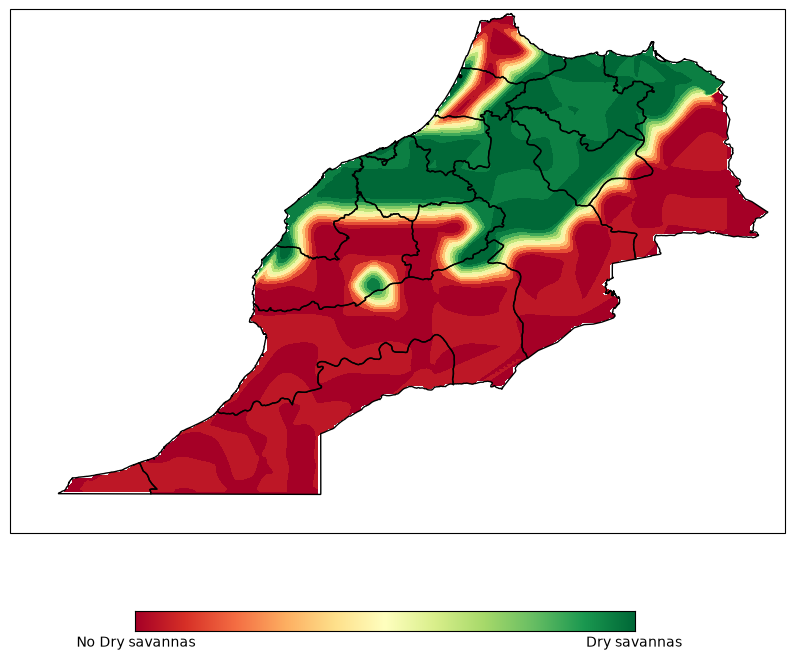

In [ ]:
plot_map(regions_merge[regions_merge["ISO3"] == "MAR"],lon_wb=-14,lon_eb=-0.7,lat_nb=36,lat_sb=27,geojson_paths=jsons)

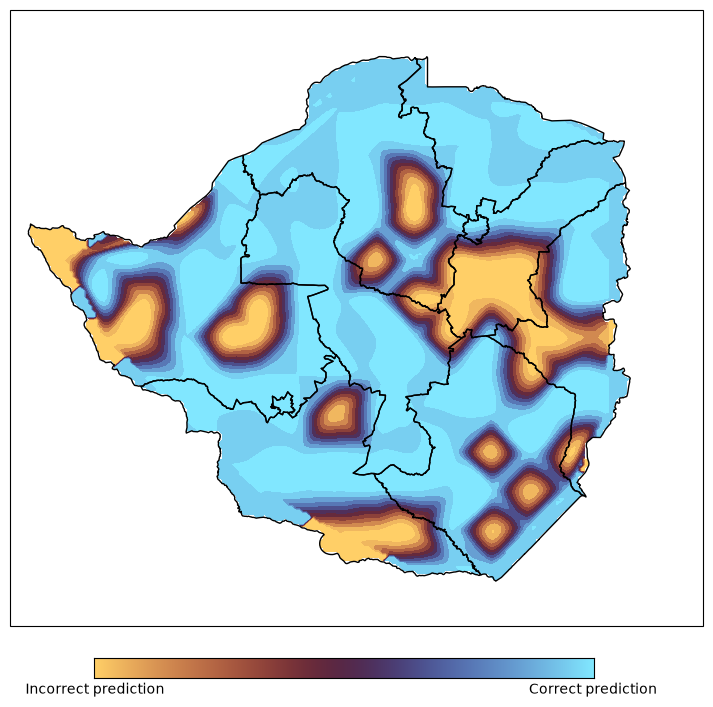

In [ ]:
plot_missclassified(regions_merge[regions_merge["ISO3"] == "ZWE"],prediction=bin_class.predict(X_test_ZWE),
                    lon_wb=25,lon_eb=34,lat_nb=-15,lat_sb=-23,geojson_paths=jsons)